<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_36_Characterstics_of_Attention_Adjustment_Magnitudes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from datasets import load_dataset

import torch
from transformers import AutoModelForCausalLM, GPT2Tokenizer
import torch.nn.functional as F

# Part 1: Model, tokens, projection vectors

## Task_1:
- Import GPT-2-large and its tokenizer. Define a variable for the
number of transformer layers.
Create and implant hook functions into all attn.c_proj layers
that detaches the output of the attention block and stores it in a
dictionary with keys indicating the layer from which the vectors were
taken.
The online code file shows how to import the test set from
the “Rotten Tomatoes” dataset via the Hugging Face function
load_dataset. Explore the dataset by examining the number of
samples it contains and by printing out an example text sample.

In [2]:
# load GPT2 model and tokenizer
model = AutoModelForCausalLM.from_pretrained('gpt2-large')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

model.eval()


config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.25GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [3]:
n_layers = model.config.n_layer

In [4]:
n_layers

36

In [7]:
# hook the attention vectors
activations = {}

def implant_hook(layer_number):
  def hook(module,input,output):
    activations[f'attn_L{layer_number}'] = output.detach()
  return hook

In [8]:
# implant the hooks
handles = []
for i in range(n_layers):
  h = model.transformer.h[i].attn.c_proj.register_forward_hook(implant_hook(i))
  handles.append(h)

In [9]:
# load a dataset
dataset = load_dataset('cornell-movie-review-data/rotten_tomatoes', split='test')
dataset

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

test.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8530 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1066 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 1066
})

In [10]:
dataset[30]

{'text': "what's so striking about jolie's performance is that she never lets her character become a caricature -- not even with that radioactive hair .",
 'label': 1}

In [15]:
dataset[857]

{'text': "this is sandler running on empty , repeating what he's already done way too often .",
 'label': 0}

## Task_2:
- Create a batch of 64 text sequences. The movie reviews have varying
lengths, which means you’ll need to use padding to create a batch.
Remember that you need to define a pad token in the GPT-2
tokenizer object. Also remember that the shorter token sequences
are padded to the length of the longest token sequence in the batch.
Because different sequences have different lengths, you will need a
Boolean mask of size batch × tokens that contains True for valid
tokens, and False for padding tokens. This is different from the
attention_mask variable produced by the tokenizer, and will be used
later in the project. Visualize the Boolean mask using plt.pcolor
as in Figure 6.30A, and a histogram of sequence lengths as in Figure
6.30B

In [16]:
batchsize = 64

txt = [dataset[i]['text'] for i in range(batchsize)]

tokenizer.pad_token =tokenizer.eos_token
tokens = tokenizer(txt,padding=True,return_tensors='pt')
n_tokens = tokens['input_ids'].shape[-1]

# create the boolean attention mask
token_mask = tokens['attention_mask'].to(torch.bool)


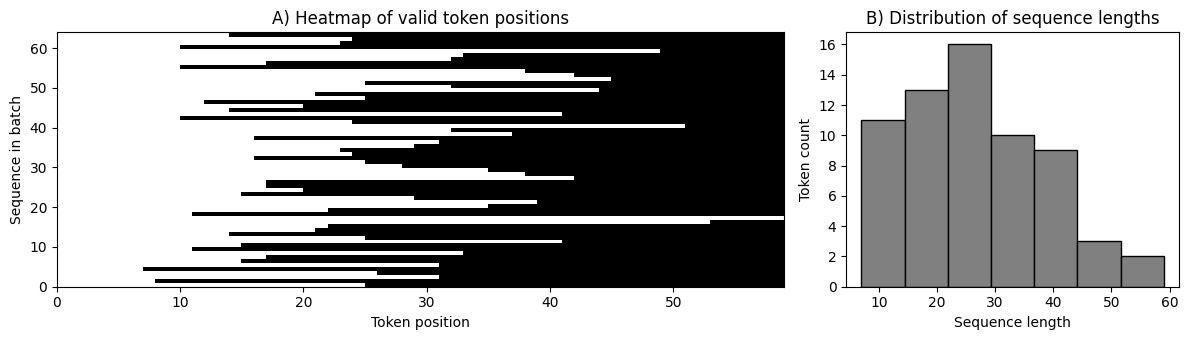

In [31]:
# visualize
fig = plt.figure(figsize=(12,3.5))
gs = GridSpec(1,3,figure=fig)
ax0 = fig.add_subplot(gs[:-1])
ax1 = fig.add_subplot(gs[-1])

ax0.pcolor(token_mask,cmap='gray')
ax0.set(xlabel='Token position',ylabel='Sequence in batch',title='A) Heatmap of valid token positions')
ax0.spines.top.set_visible(True) # switched off by default, but I want the top spine here

ax1.hist(token_mask.sum(dim=-1),bins='fd',color='gray',edgecolor='k')
ax1.set(xlabel='Sequence length',ylabel='Token count',title='B) Distribution of sequence lengths')

plt.tight_layout()
plt.show()

## Task_3:
- Run the tokens through the model to get the attention activations.
Print out the names and shapes of the activations tensors.

In [32]:

with torch.no_grad():
  outputs = model(**tokens)

for k,v in activations.items():
  print(f'{k:>8} has shape {list(v.shape)}')

 attn_L0 has shape [64, 59, 1280]
 attn_L1 has shape [64, 59, 1280]
 attn_L2 has shape [64, 59, 1280]
 attn_L3 has shape [64, 59, 1280]
 attn_L4 has shape [64, 59, 1280]
 attn_L5 has shape [64, 59, 1280]
 attn_L6 has shape [64, 59, 1280]
 attn_L7 has shape [64, 59, 1280]
 attn_L8 has shape [64, 59, 1280]
 attn_L9 has shape [64, 59, 1280]
attn_L10 has shape [64, 59, 1280]
attn_L11 has shape [64, 59, 1280]
attn_L12 has shape [64, 59, 1280]
attn_L13 has shape [64, 59, 1280]
attn_L14 has shape [64, 59, 1280]
attn_L15 has shape [64, 59, 1280]
attn_L16 has shape [64, 59, 1280]
attn_L17 has shape [64, 59, 1280]
attn_L18 has shape [64, 59, 1280]
attn_L19 has shape [64, 59, 1280]
attn_L20 has shape [64, 59, 1280]
attn_L21 has shape [64, 59, 1280]
attn_L22 has shape [64, 59, 1280]
attn_L23 has shape [64, 59, 1280]
attn_L24 has shape [64, 59, 1280]
attn_L25 has shape [64, 59, 1280]
attn_L26 has shape [64, 59, 1280]
attn_L27 has shape [64, 59, 1280]
attn_L28 has shape [64, 59, 1280]
attn_L29 has s

In [33]:
outputs.logits.shape

torch.Size([64, 59, 50257])

# Part 2: Laminar profile of attention adjustment magnitudes

## Task_1:
- To understand why I asked you to recreate the token mask as a
Boolean matrix, check the sizes of the outputs of the following two
lines of code:
activations[’attn_L4’][tokens[’attention_mask’]]
activations[’attn_L4’][token_mask] # Boolean mask
Also inspect the outcome of the first line and notice the redundancies

In [38]:
# on broadcast-masking
print(activations['attn_L4'][tokens['attention_mask']].shape)
print(activations['attn_L4'][token_mask].shape)

torch.Size([64, 59, 59, 1280])
torch.Size([1691, 1280])


In [39]:
activations['attn_L4'][tokens['attention_mask']][:,1,1,:]

tensor([[-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162],
        [-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162],
        [-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162],
        ...,
        [-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162],
        [-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162],
        [-0.0693, -0.1932,  0.0551,  ...,  0.2122, -0.0843,  0.1162]])

## Task_2:
- Loop over all transformer layers. For each attention block, extract
the logarithm of the vector norms from valid tokens — excluding the
first token in the sequence. Use NumPy functions for the calculations.
Make a histogram of the log-norms and visualize in line plots
as in Figure 6.31A. Then calculate the average and standard devia
tion of the log-norms and show in a scatter plot with error bars as
in Figure 6.31B.

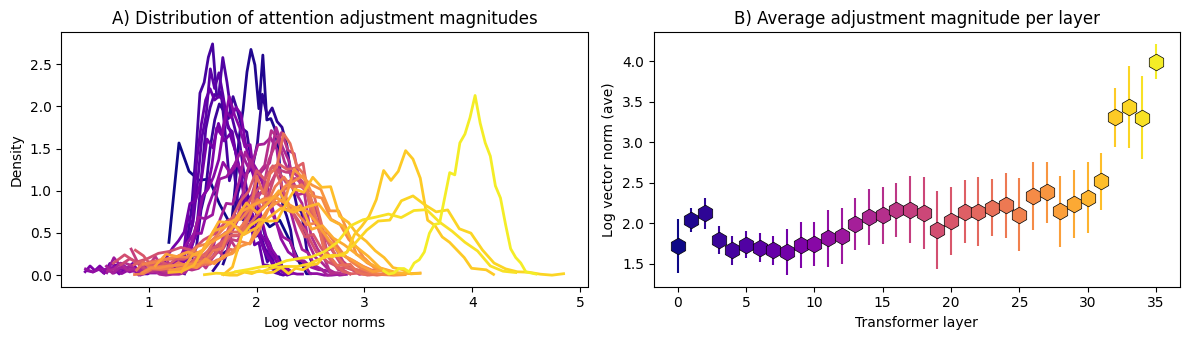

In [40]:
_,axs = plt.subplots(1,2,figsize=(12,3.5))

for layeri in range(n_layers):

  # get the adjustments (ignoring the first token)
  att_projs = activations[f'attn_L{layeri}'][:,1:,:][token_mask[:,1:]]
  att_projs = att_projs.numpy() # using numpy here

  # histogram of log-norms
  norms = np.log( np.linalg.norm(att_projs,axis=-1) )
  y,x = np.histogram(norms,bins='fd',density=True)

  # and visualize
  axs[0].plot(x[:-1],y,color=plt.cm.plasma(layeri/n_layers),linewidth=2,label=f'L{layeri}')
  axs[1].errorbar(layeri,np.mean(norms),np.std(norms),color=plt.cm.plasma(layeri/n_layers))
  axs[1].plot(layeri,np.mean(norms),'kh',markeredgewidth=.5,markersize=12,markerfacecolor=plt.cm.plasma(layeri/n_layers))

# plot adjustments
axs[0].set(xlabel='Log vector norms',ylabel='Density',title='A) Distribution of attention adjustment magnitudes')
axs[1].set(xlabel='Transformer layer',ylabel='Log vector norm (ave)',title='B) Average adjustment magnitude per layer')

plt.tight_layout()
plt.show()

# Part 3: Adjustment norm by token position

## Task_1:
- In a for-loop over transformer layers, calculate the log-norms of all
attention adjustments vectors, this time using PyTorch. Average
together the log-norms, separately per token position — but only
average the valid (non-padding) tokens. Then convert to NumPy
such that the result is a NumPy array of size layer × token positions
in which each element is the average attention adjustment magnitude
(excluding pad tokens).
Show the results in a heatmap of token position (x-axis) by
transformer layer (y-axis) as in Figure 6.32. The color limits
correspond to the 5% and 95% of the log-norm distributions. Finally,
make a scatter plot of the number of valid tokens per token position,
as in Figure 6.33.

In [41]:

# reminder for reference
activations['attn_L4'].shape

torch.Size([64, 59, 1280])

In [42]:
# example of averaging only the valid tokens
all_norms = torch.norm(activations[f'attn_L{layeri}'],dim=-1)
ave_norms = np.zeros(n_tokens)

for t in range(n_tokens):
  this_pos_mask = token_mask[:,t]
  valid_norms = all_norms[this_pos_mask,:]
  ave_norms[t] = valid_norms.mean().item()

all_norms.shape, ave_norms.shape

(torch.Size([64, 59]), (59,))

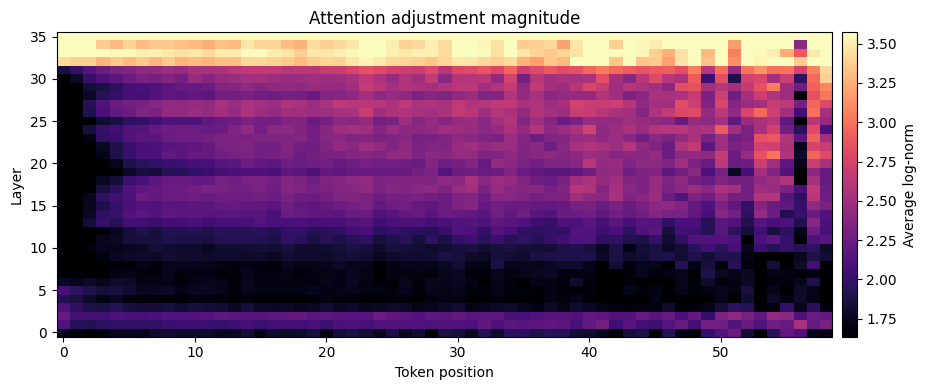

In [43]:
plt.figure(figsize=(10,4))

X = np.zeros((n_layers,n_tokens))

# loop over layers
for layeri in range(n_layers):

  # get the norms
  norms = torch.norm(activations[f'attn_L{layeri}'],dim=-1)

  # average all the norms for each position, only for rows with mask=True
  norm_by_pos = np.log(np.array([norms[token_mask[:,t],t].mean().item() for t in range(n_tokens)]))
  X[layeri,:] = norm_by_pos

# percentile-based color values
cmin,cmax = np.percentile(X.flatten(),[5,95])

# and visualize
plt.imshow(X,origin='lower',vmin=cmin,vmax=cmax,aspect='auto',cmap='magma')
plt.colorbar(label='Average log-norm',pad=.01)
plt.gca().set(xlabel='Token position',ylabel='Layer',title='Attention adjustment magnitude')

plt.tight_layout()
plt.show()


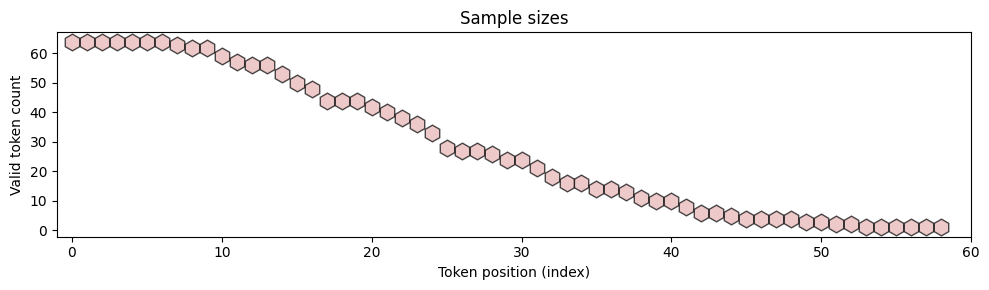

In [44]:
plt.figure(figsize=(10,3))
plt.plot(token_mask.sum(dim=0),'kh',markersize=12,markerfacecolor=[.9,.7,.7,.7])
plt.gca().set(xlabel='Token position (index)',ylabel='Valid token count',
              xlim=[-1,n_tokens+1],title='Sample sizes')

plt.tight_layout()
plt.show()

# Part 4: Predicting adjustment norm from token position

## Task_1:
- Create a design matrix that contains two columns: a column of all
1’s (the intercept term) and a column of integers from 0 to N-1,
where N is the number of token positions to include in the analysis.
As you know from Part 3, the sample size decreases with increasing
position index; therefore, set N = 30 instead of 59 to avoid using
very small sample sizes in the analysis.
In a for-loop over transformer layers, extract the average log
norm of the valid (non-pad) tokens for each position, just like in
Part 3. That vector of average norms is the dependent variable.
Use NumPy’s linalg.lstsq function to fit the layer-specific data to
the design matrix. Exclude the first token in the sequence from the
analysis.
Visualize the data as in Figure 6.34. Panel A shows the data
(the dependent variable), panel B shows the β0 (intercept) parame
ters, and panel C shows the β1 (slope) parameters.